In [ ]:

import pandas as pd
import numpy as np
from google.colab import files

rng = np.random.default_rng(42)
n = 400

services = [
    "Academic Records", "Certification", "IT Support",
    "Scholarship Inquiry", "Enrollment", "Financial Assistance"
]

office_map = {
    "Academic Records": "Registrar",
    "Certification": "Registrar",
    "IT Support": "IT Services",
    "Scholarship Inquiry": "Scholarship Office",
    "Enrollment": "Student Affairs",
    "Financial Assistance": "Finance Office"
}

service = rng.choice(services, n)
queue = rng.integers(0, 26, n)
documents = rng.choice(["Yes", "No"], n, p=[0.78, 0.22])

sla_map = {
    "Academic Records": 3, "Certification": 4,
    "IT Support": 2, "Scholarship Inquiry": 5,
    "Enrollment": 3, "Financial Assistance": 5
}
sla = np.array([sla_map[s] for s in service])

processing = np.maximum(
    1,
    np.round(
        sla * 0.65 + queue * 0.12
        + np.where(documents == "No", 2, 0)
        + rng.normal(0, 1.5, n)
    )
).astype(float)

status = rng.choice(
    ["Completed", "Pending", "Cancelled"],
    n, p=[0.72, 0.12, 0.16]
)
processing[np.array(status) != "Completed"] = np.nan

dates = (
    pd.Timestamp("2026-01-01")
    + pd.to_timedelta(rng.integers(0, 280, n), unit="D")
)

df = pd.DataFrame({
    "Request_ID": [f"SR{i:04d}" for i in range(1, n + 1)],
    "Service_Type": service,
    "Requester_Type": rng.choice(
        ["Student", "Faculty", "Staff"], n, p=[0.82, 0.10, 0.08]
    ),
    "Submission_Date": dates.strftime("%Y-%m-%d"),
    "Requested_Channel": rng.choice(["Portal", "Email", "Walk-in"], n),
    "Priority": rng.choice(["Low", "Normal", "High"], n),
    "Assigned_Office": [office_map[s] for s in service],
    "Queue_Length": queue,
    "Required_Documents_Complete": documents,
    "Processing_Days": processing,
    "SLA_Days": sla,
    "Status": status,
    "Reopened": rng.choice(["Yes", "No"], n, p=[0.08, 0.92]),
    "Satisfaction_Score": rng.choice(
        [1, 2, 3, 4, 5, np.nan], n
    )
})


df.loc[5, "Service_Type"] = " IT Support "
df.loc[12, "Queue_Length"] = -2
df.loc[20, "Submission_Date"] = "not-a-date"
df.loc[30, "Priority"] = " normal "
df.loc[40, "Satisfaction_Score"] = -1
df.loc[80, "Request_ID"] = df.loc[79, "Request_ID"]

filename = "student_service_requests_synthetic.csv"
df.to_csv(filename, index=False)

print("Dataset created:", filename)
print("Dataset shape:", df.shape)
display(df.head(10))

files.download(filename)







Dataset created: student_service_requests_synthetic.csv
Dataset shape: (400, 14)


,Request_ID,Service_Type,Requester_Type,Submission_Date,Requested_Channel,Priority,Assigned_Office,Queue_Length,Required_Documents_Complete,Processing_Days,SLA_Days,Status,Reopened,Satisfaction_Score
0,SR0001,Academic Records,Student,2026-04-06,Email,Normal,Registrar,25,Yes,8.0,3,Completed,No,4.0
1,SR0002,Enrollment,Student,2026-09-28,Walk-in,Normal,Student Affairs,20,No,8.0,3,Completed,No,4.0
2,SR0003,Scholarship Inquiry,Student,2026-06-07,Email,High,Scholarship Office,8,No,7.0,5,Completed,No,4.0
3,SR0004,IT Support,Student,2026-03-16,Email,Low,IT Services,25,Yes,6.0,2,Completed,No,1.0
4,SR0005,IT Support,Student,2026-01-02,Email,High,IT Services,12,No,NaN,2,Pending,No,2.0
5,SR0006,IT Support,Student,2026-05-01,Portal,Low,Finance Office,13,No,NaN,5,Pending,No,1.0
6,SR0007,Academic Records,Student,2026-10-04,Walk-in,Normal,Registrar,11,Yes,2.0,3,Completed,No,5.0
7,SR0008,Enrollment,Student,2026-05-02,Portal,High,Student Affairs,3,No,5.0,3,Completed,No,5.0
8,SR0009,Certification,Faculty,2026-07-15,Walk-in,Normal,Registrar,24,Yes,6.0,4,Completed,No,2.0
9,SR0010,Academic Records,Student,2026-03-12,Walk-in,High,Registrar,0,No,2.0,3,Completed,No,2.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import pandas as pd
from google.colab import files
from IPython.display import display


uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("PART I: DATASET LOADING AND UNDERSTANDING")
print("=" * 55)

print("\n1. FIRST 10 ROWS")
display(df.head(10))


print("\n2. DATASET SHAPE")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


print("\n3. COLUMN NAMES AND DATA TYPES")
print(df.dtypes)

print("\n4. DATASET INFORMATION")
df.info()


print("\n5. CATEGORICAL FREQUENCY COUNTS")

categorical_columns = [
    "Service_Type",
    "Requester_Type",
    "Requested_Channel",
    "Priority",
    "Assigned_Office",
    "Required_Documents_Complete",
    "Status",
    "Reopened"
]

for column in categorical_columns:
    if column in df.columns:
        print(f"\n{column}:")
        display(df[column].value_counts(dropna=False))



print("\n6. VARIABLE IDENTIFICATION")

identifier = "Request_ID" if "Request_ID" in df.columns else None


excluded_columns = {
    "Request_ID",
    "Processing_Days",
    "Status",
    "Reopened",
    "Satisfaction_Score",
    "SLA_Breached"
}

predictors = [col for col in df.columns
              if col not in excluded_columns]

target = "SLA_Breached"  # Derived in Part II

print("Identifier:", identifier)
print("Target variable:", target, "(to be derived in Part II)")
print("Potential submission-time predictors:", predictors)

print("\nCategorical variables:")
display(df.select_dtypes(include=["object", "category"]).columns.tolist())

print("\nNumerical variables:")
display(df.select_dtypes(include="number").columns.tolist())

print("\n8. DATA COLLECTION METHOD")
print("""
Data can be collected through the student service portal,
online forms, or a service-request database. Each submitted
request should be recorded with its service type, requester,
submission date, requested channel, priority, assigned office,
queue length, document completeness, SLA target, and status.

Data should be exported to CSV or retrieved through an authorized
database/API connection. Records should be validated, duplicates
checked, and sensitive personal information protected.
""")


expected_columns = [
    "Request_ID",
    "Service_Type",
    "Requester_Type",
    "Submission_Date",
    "Requested_Channel",
    "Priority",
    "Assigned_Office",
    "Queue_Length",
    "Required_Documents_Complete",
    "Processing_Days",
    "SLA_Days",
    "Status",
    "Reopened",
    "Satisfaction_Score"
]

print("\n9. EXPECTED SCHEMA CHECK")
missing_columns = [
    col for col in expected_columns if col not in df.columns
]
extra_columns = [
    col for col in df.columns if col not in expected_columns
]

print("Missing expected columns:", missing_columns)
print("Additional columns:", extra_columns)

if not missing_columns:
    print("All expected columns are present.")
else:
    print("Document the actual schema and adapt later code accordingly.")


Saving student_service_requests_synthetic (3).csv to student_service_requests_synthetic (3).csv
PART I: DATASET LOADING AND UNDERSTANDING

1. FIRST 10 ROWS


,Request_ID,Service_Type,Requester_Type,Submission_Date,Requested_Channel,Priority,Assigned_Office,Queue_Length,Required_Documents_Complete,Processing_Days,SLA_Days,Status,Reopened,Satisfaction_Score
0,SR0001,Academic Records,Student,2026-04-06,Email,Normal,Registrar,25,Yes,8.0,3,Completed,No,4.0
1,SR0002,Enrollment,Student,2026-09-28,Walk-in,Normal,Student Affairs,20,No,8.0,3,Completed,No,4.0
2,SR0003,Scholarship Inquiry,Student,2026-06-07,Email,High,Scholarship Office,8,No,7.0,5,Completed,No,4.0
3,SR0004,IT Support,Student,2026-03-16,Email,Low,IT Services,25,Yes,6.0,2,Completed,No,1.0
4,SR0005,IT Support,Student,2026-01-02,Email,High,IT Services,12,No,NaN,2,Pending,No,2.0
5,SR0006,IT Support,Student,2026-05-01,Portal,Low,Finance Office,13,No,NaN,5,Pending,No,1.0
6,SR0007,Academic Records,Student,2026-10-04,Walk-in,Normal,Registrar,11,Yes,2.0,3,Completed,No,5.0
7,SR0008,Enrollment,Student,2026-05-02,Portal,High,Student Affairs,3,No,5.0,3,Completed,No,5.0
8,SR0009,Certification,Faculty,2026-07-15,Walk-in,Normal,Registrar,24,Yes,6.0,4,Completed,No,2.0
9,SR0010,Academic Records,Student,2026-03-12,Walk-in,High,Registrar,0,No,2.0,3,Completed,No,2.0



2. DATASET SHAPE
Number of rows: 400
Number of columns: 14

3. COLUMN NAMES AND DATA TYPES
Request_ID                      object
Service_Type                    object
Requester_Type                  object
Submission_Date                 object
Requested_Channel               object
Priority                        object
Assigned_Office                 object
Queue_Length                     int64
Required_Documents_Complete     object
Processing_Days                float64
SLA_Days                         int64
Status                          object
Reopened                        object
Satisfaction_Score             float64
dtype: object

4. DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 14 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Request_ID                   400 non-null    object 
 1   Service_Type                 400 non-nul

,count
Service_Type,
Enrollment,77
IT Support,72
Academic Records,69
Certification,66
Scholarship Inquiry,61
Financial Assistance,54
IT Support,1



Requester_Type:


...


6. VARIABLE IDENTIFICATION
Identifier: Request_ID
Target variable: SLA_Breached (to be derived in Part II)
Potential submission-time predictors: ['Service_Type', 'Requester_Type', 'Submission_Date', 'Requested_Channel', 'Priority', 'Assigned_Office', 'Queue_Length', 'Required_Documents_Complete', 'SLA_Days']

Categorical variables:


['Request_ID',
 'Service_Type',
 'Requester_Type',
 'Submission_Date',
 'Requested_Channel',
 'Priority',
 'Assigned_Office',
 'Required_Documents_Complete',
 'Status',
 'Reopened']


Numerical variables:


['Queue_Length', 'Processing_Days', 'SLA_Days', 'Satisfaction_Score']


8. DATA COLLECTION METHOD

Data can be collected through the student service portal,
online forms, or a service-request database. Each submitted
request should be recorded with its service type, requester,
submission date, requested channel, priority, assigned office,
queue length, document completeness, SLA target, and status.

Data should be exported to CSV or retrieved through an authorized
database/API connection. Records should be validated, duplicates
checked, and sensitive personal information protected.


9. EXPECTED SCHEMA CHECK
Missing expected columns: []
Additional columns: []
All expected columns are present.


In [ ]:

import pandas as pd
import numpy as np
from IPython.display import display

print("PART II: DATA QUALITY AND FEATURE ENGINEERING")
print("=" * 60)


df_quality = df.copy()


print("\n1. MISSING VALUES")
display(
    df_quality.isnull().sum()
    .rename("Missing_Count")
    .to_frame()
)

print("\n2. DUPLICATE REQUEST IDs")
if "Request_ID" in df_quality.columns:
    print("Duplicate Request_ID count:",
          df_quality["Request_ID"].duplicated().sum())

print("\n3. INCONSISTENT CATEGORICAL VALUES")
categorical_columns = [
    "Service_Type",
    "Requester_Type",
    "Requested_Channel",
    "Priority",
    "Assigned_Office",
    "Required_Documents_Complete",
    "Status",
    "Reopened"
]

for col in categorical_columns:
    if col in df_quality.columns:
        print(f"\n{col}:")
        display(df_quality[col].value_counts(dropna=False))

print("\n4. INVALID SUBMISSION DATES")
if "Submission_Date" in df_quality.columns:
    parsed_dates = pd.to_datetime(
        df_quality["Submission_Date"], errors="coerce"
    )
    invalid_dates = parsed_dates.isna()
    print("Invalid or missing dates:", int(invalid_dates.sum()))

print("\n5. NEGATIVE NUMERIC VALUES")
numeric_check = [
    "Queue_Length",
    "Processing_Days",
    "SLA_Days",
    "Satisfaction_Score"
]

for col in numeric_check:
    if col in df_quality.columns:
        numeric_values = pd.to_numeric(
            df_quality[col], errors="coerce"
        )
        print(f"{col}:",
              int((numeric_values < 0).sum()),
              "negative value(s)")



print("\n6. CLEANING DATA")


for col in df_quality.select_dtypes(include="object").columns:
    df_quality[col] = df_quality[col].str.strip()


capitalization_map = {
    "Priority": {
        "low": "Low", "normal": "Normal", "high": "High"
    },
    "Required_Documents_Complete": {
        "yes": "Yes", "no": "No"
    },
    "Reopened": {
        "yes": "Yes", "no": "No"
    },
    "Status": {
        "completed": "Completed",
        "pending": "Pending",
        "open": "Open",
        "cancelled": "Cancelled",
        "canceled": "Cancelled"
    }
}

for col, mapping in capitalization_map.items():
    if col in df_quality.columns:
        df_quality[col] = df_quality[col].apply(
            lambda x: mapping.get(x.lower(), x)
            if isinstance(x, str) else x
        )

if "Submission_Date" in df_quality.columns:
    df_quality["Submission_Date"] = pd.to_datetime(
        df_quality["Submission_Date"], errors="coerce"
    )

for col in numeric_check:
    if col in df_quality.columns:
        df_quality[col] = pd.to_numeric(
            df_quality[col], errors="coerce"
        )


if "Request_ID" in df_quality.columns:
    before = len(df_quality)
    df_quality = df_quality.drop_duplicates(
        subset=["Request_ID"], keep="first"
    ).copy()
    print("Duplicate-ID records removed:", before - len(df_quality))


nonnegative_columns = [
    "Queue_Length", "Processing_Days", "SLA_Days"
]

for col in nonnegative_columns:
    if col in df_quality.columns:
        df_quality.loc[df_quality[col] < 0, col] = np.nan


if "Satisfaction_Score" in df_quality.columns:
    invalid_score = (
        (df_quality["Satisfaction_Score"] < 1) |
        (df_quality["Satisfaction_Score"] > 5)
    )
    df_quality.loc[invalid_score, "Satisfaction_Score"] = np.nan



print("\n7. FEATURE ENGINEERING")


if "Submission_Date" in df_quality.columns:
    df_quality["Submission_Weekday"] = (
        df_quality["Submission_Date"].dt.day_name()
    )
    print("Created Submission_Weekday.")


if "Queue_Length" in df_quality.columns:
    df_quality["Queue_Category"] = pd.cut(
        df_quality["Queue_Length"],
        bins=[-np.inf, 5, 15, np.inf],
        labels=["Low", "Medium", "High"]
    )
    print("Created Queue_Category.")


if {"Processing_Days", "SLA_Days"}.issubset(df_quality.columns):
    eligible = (
        df_quality["Processing_Days"].notna() &
        df_quality["SLA_Days"].notna()
    )

    df_quality["SLA_Breached"] = np.nan
    df_quality.loc[eligible, "SLA_Breached"] = (
        df_quality.loc[eligible, "Processing_Days"] >
        df_quality.loc[eligible, "SLA_Days"]
    ).astype(int)

    print("Created SLA_Breached for records with known processing and SLA days.")



print("\n8. ELIGIBLE LABELED MODELING SUBSET")

if {"Status", "SLA_Breached"}.issubset(df_quality.columns):
    completed_mask = (
        df_quality["Status"].astype("string").str.lower()
        .eq("completed")
    )

    modeling_df = df_quality[
        completed_mask & df_quality["SLA_Breached"].notna()
    ].copy()

    print("Total cleaned records:", len(df_quality))
    print("Completed records with known SLA outcome:",
          len(modeling_df))

    print("\nSLA_Breached distribution:")
    display(modeling_df["SLA_Breached"].value_counts().sort_index())

    print("\nSLA_Breached proportions:")
    display(modeling_df["SLA_Breached"].value_counts(
        normalize=True
    ).sort_index().round(3))
else:
    modeling_df = pd.DataFrame()
    print("Cannot create modeling subset: required columns are missing.")



print("\n9. CLEANED DATA PREVIEW")
display(df_quality.head(10))

print("\n10. FINAL DATA QUALITY SUMMARY")
print("Rows:", df_quality.shape[0])
print("Columns:", df_quality.shape[1])
print("Remaining missing values:")
display(df_quality.isnull().sum().to_frame("Missing_Count"))


df_quality.to_csv("student_service_requests_cleaned.csv", index=False)
modeling_df.to_csv("student_service_requests_modeling.csv", index=False)

print("\nSaved:")
print("- student_service_requests_cleaned.csv")
print("- student_service_requests_modeling.csv")


from google.colab import files
files.download("student_service_requests_cleaned.csv")
files.download("student_service_requests_modeling.csv")


PART II: DATA QUALITY AND FEATURE ENGINEERING

1. MISSING VALUES


,Missing_Count
Request_ID,0
Service_Type,0
Requester_Type,0
Submission_Date,0
Requested_Channel,0
Priority,0
Assigned_Office,0
Queue_Length,0
Required_Documents_Complete,0
Processing_Days,112



2. DUPLICATE REQUEST IDs
Duplicate Request_ID count: 1

3. INCONSISTENT CATEGORICAL VALUES

Service_Type:


,count
Service_Type,
Enrollment,77
IT Support,72
Academic Records,69
Certification,66
Scholarship Inquiry,61
Financial Assistance,54
IT Support,1



Requester_Type:


...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


PART III: EXPLORATORY DATA ANALYSIS

1. MOST COMMON SERVICE TYPE


,Request_Count
Service_Type,
Enrollment,77
IT Support,73
Academic Records,69
Certification,66
Scholarship Inquiry,61
Financial Assistance,53


Finding: The most common service type is Enrollment, with 77 requests.

2. SLA BREACH RATE BY ASSIGNED OFFICE


,Completed_Requests,SLA_Breaches,SLA_Breach_Rate,SLA_Breach_Rate_Percent
Assigned_Office,,,,
IT Services,46,32,0.695652,69.57
Registrar,102,58,0.568627,56.86
Student Affairs,54,30,0.555556,55.56
Scholarship Office,46,19,0.413043,41.30
Finance Office,39,12,0.307692,30.77


Finding: IT Services has the highest observed SLA breach rate at 69.57% among offices with eligible completed requests.

3. QUEUE CATEGORY AND SLA BREACH RATE


,Completed_Requests,SLA_Breaches,SLA_Breach_Rate,SLA_Breach_Rate_Percent
Queue_Category,,,,
Low,66,17,0.257576,25.76
Medium,99,44,0.444444,44.44
High,121,89,0.735537,73.55


Finding: The High queue category has the highest observed SLA breach rate.

4. CHART 1: REQUEST VOLUME BY SERVICE TYPE


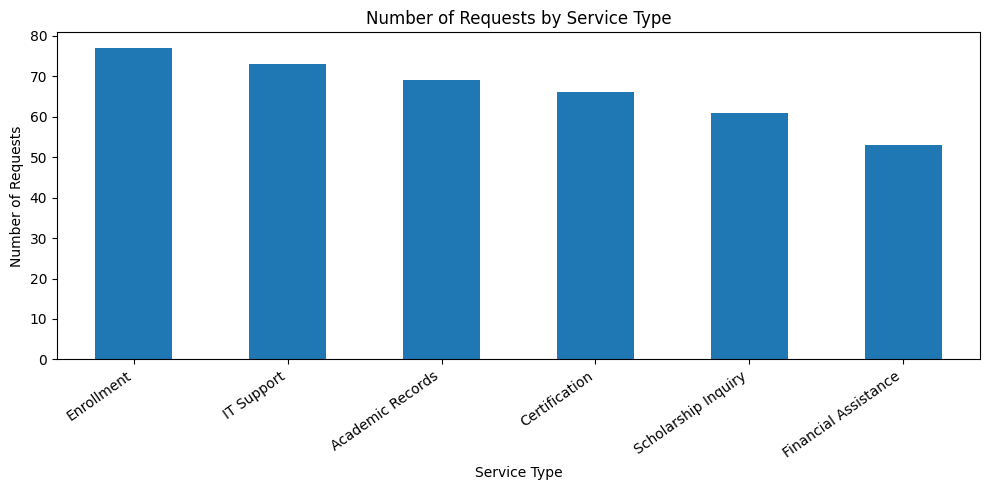

Interpretation: This chart compares request volume across service types. The tallest bar represents the service type with the greatest demand.

5. CHART 2: SLA BREACH RATE BY QUEUE CATEGORY


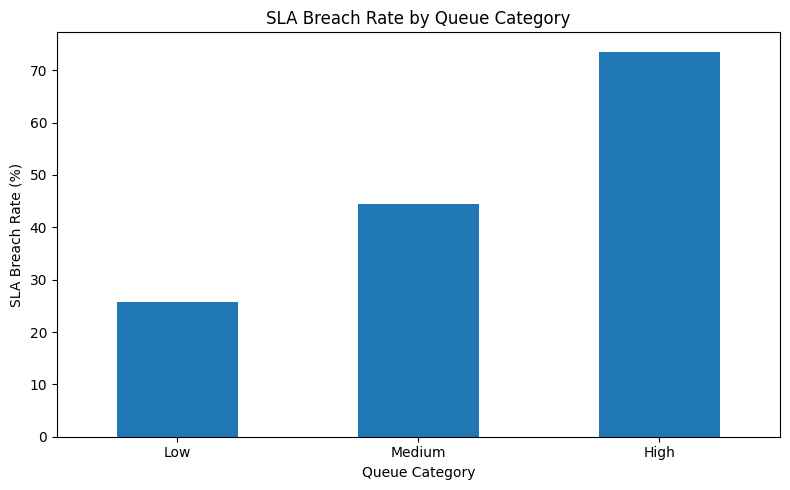

Interpretation: This chart compares the percentage of completed requests that exceeded their SLA across queue categories. A higher bar indicates a higher observed breach rate. This is an association, not proof that queue length causes SLA breaches.

6. EDA SUMMARY
Total records in cleaned dataset: 399
Completed records with known SLA outcomes: 287

Most common service type: Enrollment
Office with highest observed breach rate: IT Services
Queue category with highest observed breach rate: High


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("PART III: EXPLORATORY DATA ANALYSIS")
print("=" * 60)


eda_df = df_quality.copy()


if "SLA_Breached" not in eda_df.columns:
    raise ValueError("Run Part II first to create SLA_Breached.")

completed_df = eda_df[
    eda_df["Status"].astype("string").str.lower().eq("completed")
    & eda_df["SLA_Breached"].notna()
].copy()

if completed_df.empty:
    raise ValueError(
        "No completed requests with known SLA outcomes were found."
    )

completed_df["SLA_Breached"] = completed_df["SLA_Breached"].astype(int)


print("\n1. MOST COMMON SERVICE TYPE")

service_counts = eda_df["Service_Type"].value_counts(dropna=False)
display(service_counts.to_frame("Request_Count"))

if not service_counts.empty:
    top_service = service_counts.idxmax()
    top_service_count = service_counts.max()

    print(
        f"Finding: The most common service type is "
        f"{top_service}, with {top_service_count} requests."
    )


print("\n2. SLA BREACH RATE BY ASSIGNED OFFICE")

office_stats = (
    completed_df.groupby("Assigned_Office", dropna=False)
    .agg(
        Completed_Requests=("SLA_Breached", "size"),
        SLA_Breaches=("SLA_Breached", "sum"),
        SLA_Breach_Rate=("SLA_Breached", "mean")
    )
    .sort_values("SLA_Breach_Rate", ascending=False)
)

office_stats["SLA_Breach_Rate_Percent"] = (
    office_stats["SLA_Breach_Rate"] * 100
).round(2)

display(office_stats)

if not office_stats.empty:
    highest_office = office_stats.index[0]
    highest_rate = office_stats.iloc[0]["SLA_Breach_Rate_Percent"]

    print(
        f"Finding: {highest_office} has the highest observed SLA "
        f"breach rate at {highest_rate}% among offices with "
        f"eligible completed requests."
    )


print("\n3. QUEUE CATEGORY AND SLA BREACH RATE")

if "Queue_Category" not in completed_df.columns:
    completed_df["Queue_Category"] = pd.cut(
        completed_df["Queue_Length"],
        bins=[-float("inf"), 5, 15, float("inf")],
        labels=["Low", "Medium", "High"]
    )

queue_stats = (
    completed_df.groupby("Queue_Category", observed=False)
    .agg(
        Completed_Requests=("SLA_Breached", "size"),
        SLA_Breaches=("SLA_Breached", "sum"),
        SLA_Breach_Rate=("SLA_Breached", "mean")
    )
)

queue_stats["SLA_Breach_Rate_Percent"] = (
    queue_stats["SLA_Breach_Rate"] * 100
).round(2)

display(queue_stats)

valid_queue_stats = queue_stats.dropna(
    subset=["SLA_Breach_Rate"]
)

if not valid_queue_stats.empty:
    highest_queue = valid_queue_stats[
        "SLA_Breach_Rate"
    ].idxmax()
    print(
        f"Finding: The {highest_queue} queue category has the "
        f"highest observed SLA breach rate."
    )


print("\n4. CHART 1: REQUEST VOLUME BY SERVICE TYPE")

service_plot = eda_df["Service_Type"].value_counts().sort_values(
    ascending=False
)

plt.figure(figsize=(10, 5))
service_plot.plot(kind="bar")
plt.title("Number of Requests by Service Type")
plt.xlabel("Service Type")
plt.ylabel("Number of Requests")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print(
    "Interpretation: This chart compares request volume across "
    "service types. The tallest bar represents the service type "
    "with the greatest demand."
)


print("\n5. CHART 2: SLA BREACH RATE BY QUEUE CATEGORY")

plot_stats = valid_queue_stats.copy()

plt.figure(figsize=(8, 5))
(plot_stats["SLA_Breach_Rate"] * 100).plot(kind="bar")
plt.title("SLA Breach Rate by Queue Category")
plt.xlabel("Queue Category")
plt.ylabel("SLA Breach Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(
    "Interpretation: This chart compares the percentage of "
    "completed requests that exceeded their SLA across queue "
    "categories. A higher bar indicates a higher observed breach "
    "rate. This is an association, not proof that queue length "
    "causes SLA breaches."
)


print("\n6. EDA SUMMARY")

print("Total records in cleaned dataset:", len(eda_df))
print("Completed records with known SLA outcomes:", len(completed_df))

print("\nMost common service type:", top_service)
print("Office with highest observed breach rate:", highest_office)
print("Queue category with highest observed breach rate:",
      highest_queue if not valid_queue_stats.empty else "Unavailable")


PART IV: CLASSIFICATION AND MODEL EVALUATION

1. LABELED DATASET
Eligible completed records: 287

Target distribution:


,count
SLA_Breached,
0,136
1,151



2. PREDICTOR VARIABLES
Features used: ['Service_Type', 'Requester_Type', 'Submission_Weekday', 'Requested_Channel', 'Priority', 'Assigned_Office', 'Queue_Length', 'Queue_Category', 'Required_Documents_Complete', 'SLA_Days']
Target: SLA_Breached
0 = SLA not breached
1 = SLA breached

Excluded leakage/identifier fields:
['Request_ID', 'Processing_Days', 'Status', 'Reopened', 'Satisfaction_Score']

3. TRAIN-TEST SPLIT
Training records: 229
Testing records: 58
Random state: 42
Stratified split: True

4. DECISION TREE MODEL EVALUATION
--------------------------------------------------

Confusion Matrix
Rows = actual class; columns = predicted class
Class order: 0 = Not breached, 1 = Breached
[[16 11]
 [ 7 24]]


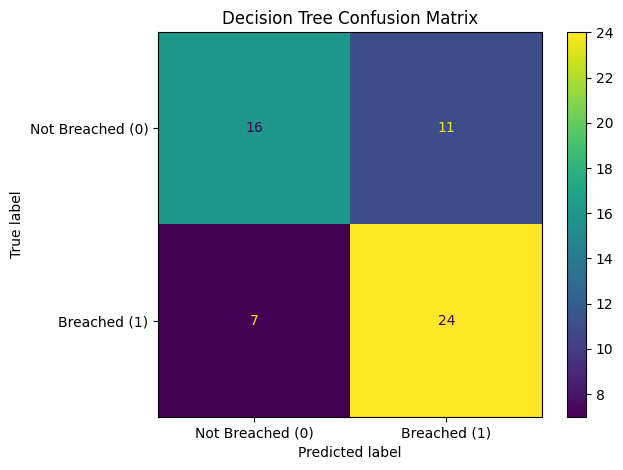


Decision Tree Metrics
Accuracy:  0.6897
Precision: 0.6857
Recall:    0.7742
F1-score:  0.7273

Classification Report
              precision    recall  f1-score   support

Not Breached       0.70      0.59      0.64        27
    Breached       0.69      0.77      0.73        31

    accuracy                           0.69        58
   macro avg       0.69      0.68      0.68        58
weighted avg       0.69      0.69      0.69        58


5. MAJORITY-CLASS BASELINE


,Metric,Decision Tree,Majority Baseline
0,Accuracy,0.6897,0.5345
1,Precision (breach),0.6857,0.5345
2,Recall (breach),0.7742,1.0000
3,F1 (breach),0.7273,0.6966



Interpretation: Compare the Decision Tree with the baseline, especially recall and F1 for the breached class. A high accuracy alone may be misleading if breaches are uncommon.

6. TOP THREE INFLUENTIAL FEATURES


,Encoded_Feature,Importance
0,numeric__Queue_Length,0.4516
33,categorical__Required_Documents_Complete_Yes,0.1784
20,categorical__Requested_Channel_Walk-in,0.0733
9,categorical__Requester_Type_Staff,0.0480
24,categorical__Assigned_Office_Finance Office,0.0364
30,categorical__Queue_Category_Low,0.0266
1,numeric__SLA_Days,0.0255
16,categorical__Submission_Weekday_Tuesday,0.0254
8,categorical__Requester_Type_Faculty,0.0227
22,categorical__Priority_Low,0.0210



Top three original predictor variables:


,Total_Importance
Original_Feature,
Queue_Length,0.4516
Required_Documents_Complete,0.1784
Requested_Channel,0.0733



7. MODEL SUMMARY
Decision Tree accuracy: 0.6897
Decision Tree breach recall: 0.7742
Decision Tree breach F1-score: 0.7273
Baseline accuracy: 0.5345
The Decision Tree has a higher breach-class F1-score than the baseline.

Top influential predictors:
- Queue_Length: 0.4516
- Required_Documents_Complete: 0.1784
- Requested_Channel: 0.0733

LIMITATIONS:
- Model performance depends on the quality and size of the dataset.
- Class imbalance can make accuracy misleading.
- Feature importance indicates model reliance, not causation.
- Predictions should support staff decisions, not replace human review.

Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:



import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("PART IV: CLASSIFICATION AND MODEL EVALUATION")
print("=" * 65)


work_df = df_quality.copy()


if "SLA_Breached" not in work_df.columns:
    if {"Processing_Days", "SLA_Days"}.issubset(work_df.columns):
        eligible = (
            work_df["Processing_Days"].notna()
            & work_df["SLA_Days"].notna()
        )
        work_df["SLA_Breached"] = np.nan
        work_df.loc[eligible, "SLA_Breached"] = (
            work_df.loc[eligible, "Processing_Days"]
            > work_df.loc[eligible, "SLA_Days"]
        ).astype(int)
    else:
        raise ValueError(
            "Cannot create SLA_Breached. Check Processing_Days and SLA_Days."
        )

if "Status" not in work_df.columns:
    raise ValueError("Status column is required to select completed requests.")

completed_mask = (
    work_df["Status"].astype("string").str.strip().str.lower()
    .eq("completed")
)

model_df = work_df[
    completed_mask & work_df["SLA_Breached"].notna()
].copy()

model_df["SLA_Breached"] = model_df["SLA_Breached"].astype(int)


print("\n1. LABELED DATASET")
print("Eligible completed records:", len(model_df))
print("\nTarget distribution:")
display(model_df["SLA_Breached"].value_counts().sort_index())

if len(model_df) < 10:
    raise ValueError(
        "Too few eligible records for a meaningful 80/20 train-test split."
    )

if model_df["SLA_Breached"].nunique() < 2:
    raise ValueError(
        "The labeled dataset contains only one target class. "
        "A binary classifier cannot be evaluated meaningfully."
    )


if "Submission_Weekday" not in model_df.columns:
    model_df["Submission_Date"] = pd.to_datetime(
        model_df["Submission_Date"], errors="coerce"
    )
    model_df["Submission_Weekday"] = (
        model_df["Submission_Date"].dt.day_name()
    )

if "Queue_Category" not in model_df.columns:
    model_df["Queue_Category"] = pd.cut(
        pd.to_numeric(model_df["Queue_Length"], errors="coerce"),
        bins=[-np.inf, 5, 15, np.inf],
        labels=["Low", "Medium", "High"]
    )


candidate_features = [
    "Service_Type",
    "Requester_Type",
    "Submission_Weekday",
    "Requested_Channel",
    "Priority",
    "Assigned_Office",
    "Queue_Length",
    "Queue_Category",
    "Required_Documents_Complete",
    "SLA_Days"
]

features = [
    col for col in candidate_features
    if col in model_df.columns
]

if len(features) < 5:
    raise ValueError(
        f"Only {len(features)} eligible predictors were found: {features}. "
        "Check the actual CSV schema and adapt the feature list."
    )

X = model_df[features].copy()
y = model_df["SLA_Breached"].astype(int)


numeric_features = [
    col for col in ["Queue_Length", "SLA_Days"]
    if col in features
]

for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")


categorical_features = [
    col for col in features if col not in numeric_features
]

for col in categorical_features:
    X[col] = X[col].apply(
        lambda value: str(value).strip()
        if pd.notna(value) else np.nan
    )

print("\n2. PREDICTOR VARIABLES")
print("Features used:", features)
print("Target: SLA_Breached")
print("0 = SLA not breached")
print("1 = SLA breached")

print("\nExcluded leakage/identifier fields:")
print([
    col for col in [
        "Request_ID", "Processing_Days", "Status",
        "Reopened", "Satisfaction_Score"
    ] if col in model_df.columns
])



class_counts = y.value_counts()

use_stratify = (
    y.nunique() == 2 and class_counts.min() >= 2
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y if use_stratify else None
)

print("\n3. TRAIN-TEST SPLIT")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Random state: 42")
print("Stratified split:", use_stratify)



numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []

if numeric_features:
    transformers.append(
        ("numeric", numeric_transformer, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("categorical", categorical_transformer, categorical_features)
    )

preprocessor = ColumnTransformer(transformers=transformers)

decision_tree = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        max_depth=5,
        class_weight="balanced"
    ))
])

decision_tree.fit(X_train, y_train)
y_pred = decision_tree.predict(X_test)



print("\n4. DECISION TREE MODEL EVALUATION")
print("-" * 50)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("\nConfusion Matrix")
print("Rows = actual class; columns = predicted class")
print("Class order: 0 = Not breached, 1 = Breached")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Breached (0)", "Breached (1)"]
)
disp.plot()
plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

dt_accuracy = accuracy_score(y_test, y_pred)
dt_precision = precision_score(
    y_test, y_pred, pos_label=1, zero_division=0
)
dt_recall = recall_score(
    y_test, y_pred, pos_label=1, zero_division=0
)
dt_f1 = f1_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

print("\nDecision Tree Metrics")
print(f"Accuracy:  {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall:    {dt_recall:.4f}")
print(f"F1-score:  {dt_f1:.4f}")

print("\nClassification Report")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Not Breached", "Breached"],
    zero_division=0
))



print("\n5. MAJORITY-CLASS BASELINE")
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_pred)
baseline_precision = precision_score(
    y_test, baseline_pred, pos_label=1, zero_division=0
)
baseline_recall = recall_score(
    y_test, baseline_pred, pos_label=1, zero_division=0
)
baseline_f1 = f1_score(
    y_test, baseline_pred, pos_label=1, zero_division=0
)

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (breach)", "Recall (breach)", "F1 (breach)"],
    "Decision Tree": [
        dt_accuracy, dt_precision, dt_recall, dt_f1
    ],
    "Majority Baseline": [
        baseline_accuracy, baseline_precision,
        baseline_recall, baseline_f1
    ]
})

display(comparison.round(4))

print(
    "\nInterpretation: Compare the Decision Tree with the baseline, "
    "especially recall and F1 for the breached class. A high accuracy "
    "alone may be misleading if breaches are uncommon."
)


print("\n6. TOP THREE INFLUENTIAL FEATURES")

fitted_preprocessor = decision_tree.named_steps["preprocessor"]
fitted_classifier = decision_tree.named_steps["classifier"]

encoded_feature_names = fitted_preprocessor.get_feature_names_out()
importances = fitted_classifier.feature_importances_

importance_df = pd.DataFrame({
    "Encoded_Feature": encoded_feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(10).round(4))


def original_feature(encoded_name):
    name = encoded_name.split("__", 1)[-1]
    for col in sorted(features, key=len, reverse=True):
        if name == col or name.startswith(col + "_"):
            return col
    return name

importance_df["Original_Feature"] = (
    importance_df["Encoded_Feature"].apply(original_feature)
)

grouped_importance = (
    importance_df.groupby("Original_Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
)

print("\nTop three original predictor variables:")
display(grouped_importance.head(3).to_frame("Total_Importance").round(4))



print("\n7. MODEL SUMMARY")
print("Decision Tree accuracy:", round(dt_accuracy, 4))
print("Decision Tree breach recall:", round(dt_recall, 4))
print("Decision Tree breach F1-score:", round(dt_f1, 4))
print("Baseline accuracy:", round(baseline_accuracy, 4))

if dt_f1 > baseline_f1:
    print("The Decision Tree has a higher breach-class F1-score than the baseline.")
elif dt_f1 < baseline_f1:
    print("The Decision Tree has a lower breach-class F1-score than the baseline.")
else:
    print("The Decision Tree and baseline have equal breach-class F1-scores.")

print("\nTop influential predictors:")
for feature, value in grouped_importance.head(3).items():
    print(f"- {feature}: {value:.4f}")

print("""
LIMITATIONS:
- Model performance depends on the quality and size of the dataset.
- Class imbalance can make accuracy misleading.
- Feature importance indicates model reliance, not causation.
- Predictions should support staff decisions, not replace human review.
""")


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Success! Both UML diagram files were created.
PNG: /content/SectionB_Michael jay Faensolin_ExamV2_UML.png
PDF: /content/SectionB_Michael jay Faensolin_ExamV2_UML.pdf


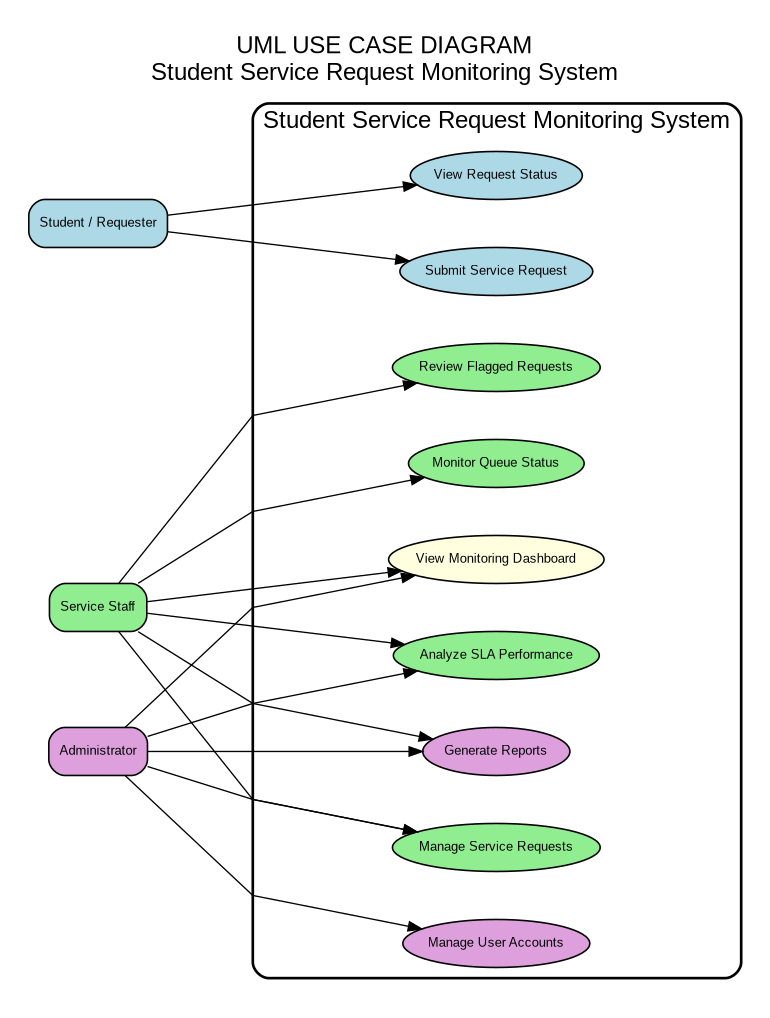

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:



!apt-get -qq update
!apt-get -qq install -y graphviz
!pip -q install graphviz

from graphviz import Digraph
from IPython.display import Image, display
from google.colab import files
from pathlib import Path

dot = Digraph(
    name="Student_Service_Request_System",
    comment="UML Use Case Diagram"
)

dot.attr(
    "graph",
    rankdir="LR",
    label="UML USE CASE DIAGRAM\nStudent Service Request Monitoring System",
    labelloc="t",
    fontsize="18",
    fontname="Arial",
    pad="0.3",
    nodesep="0.5",
    ranksep="1.0",
    splines="polyline"
)

dot.attr(
    "node",
    fontname="Arial",
    fontsize="10",
    color="black",
    penwidth="1.2"
)

dot.attr("edge", color="black", penwidth="1.0")

# Actors
dot.node("student", "Student / Requester",
         shape="box", style="rounded,filled", fillcolor="lightblue")

dot.node("staff", "Service Staff",
         shape="box", style="rounded,filled", fillcolor="lightgreen")

dot.node("admin", "Administrator",
         shape="box", style="rounded,filled", fillcolor="plum")


with dot.subgraph(name="cluster_system") as system:
    system.attr(
        label="Student Service Request Monitoring System",
        style="rounded",
        color="black",
        penwidth="2"
    )

    system.attr(
        "node",
        shape="ellipse",
        style="filled",
        fontname="Arial",
        fontsize="10"
    )

    system.node("submit", "Submit Service Request",
                fillcolor="lightblue")
    system.node("track", "View Request Status",
                fillcolor="lightblue")

    system.node("manage", "Manage Service Requests",
                fillcolor="lightgreen")
    system.node("queue", "Monitor Queue Status",
                fillcolor="lightgreen")
    system.node("sla", "Analyze SLA Performance",
                fillcolor="lightgreen")
    system.node("review", "Review Flagged Requests",
                fillcolor="lightgreen")

    system.node("dashboard", "View Monitoring Dashboard",
                fillcolor="lightyellow")
    system.node("report", "Generate Reports",
                fillcolor="plum")
    system.node("accounts", "Manage User Accounts",
                fillcolor="plum")


dot.edge("student", "submit")
dot.edge("student", "track")


dot.edge("staff", "manage")
dot.edge("staff", "queue")
dot.edge("staff", "sla")
dot.edge("staff", "review")
dot.edge("staff", "dashboard")
dot.edge("staff", "report")


dot.edge("admin", "manage")
dot.edge("admin", "sla")
dot.edge("admin", "dashboard")
dot.edge("admin", "report")
dot.edge("admin", "accounts")


base_name = "/content/SectionB_Michael jay Faensolin_ExamV2_UML"


dot.format = "png"
png_path = dot.render(
    filename=base_name,
    cleanup=True
)


dot.format = "pdf"
pdf_path = dot.render(
    filename=base_name,
    cleanup=True
)


assert Path(png_path).is_file(), "PNG file was not created."
assert Path(pdf_path).is_file(), "PDF file was not created."

print("Success! Both UML diagram files were created.")
print("PNG:", png_path)
print("PDF:", pdf_path)


display(Image(filename=png_path))


files.download(png_path)


files.download(pdf_path)
